In [2]:
import os
import re
from datetime import datetime, timedelta
import pandas as pd
import numpy as np
from plotnine import *
from plotnine import ggplot, aes, theme_minimal, labs
from plotnine import geom_point, scale_size, scale_size_continuous
from plotnine import scale_x_discrete
from geopy.distance import geodesic
import geopandas as gpd
from shapely.geometry import Point

In [3]:
# This script allows me to plot data from the MCC continuous phylogeography tree
# The SERAPHIM plotting history script made an MCC CSV that I will be using

In [4]:
# Read in the MCC CSV

FILE = "./SERAPHIM/nov2021-2024/NAm_wild-aves_nov2021-2024_ha_MCC.csv"
mcc = pd.read_csv(FILE, sep = ',')

In [5]:
mcc.head()

,node1,node2,length,startLon,startLat,endLon,endLat,endNodeL,startNodeL,startYear,endYear,tipLabel
0,6014,6015,0.134134,-77.192847,39.606088,-81.985138,37.488593,0.134134,0.000000,2021.609902,2021.744036,NaN
1,6015,9034,0.023139,-81.985138,37.488593,-84.675856,38.896095,0.157272,0.134134,2021.744036,2021.767175,NaN
2,9034,9035,0.031183,-84.675856,38.896095,-84.255735,38.488669,0.188455,0.157272,2021.767175,2021.798358,NaN
3,9035,9141,0.012011,-84.255735,38.488669,-86.741516,38.975548,0.200467,0.188455,2021.798358,2021.810369,NaN
4,9035,9036,0.015212,-84.255735,38.488669,-80.850620,36.146270,0.203668,0.188455,2021.798358,2021.813570,NaN


In [6]:
# Compute the change in latitude between start and end nodes

mcc["changeLat"] = mcc["endLat"] - mcc["startLat"]

In [7]:
# Compute the change in longitude between start and end nodes

mcc["changeLon"] = mcc["endLon"] - mcc["startLon"]

In [8]:
# Add the whole starting and ending year

mcc["startYear_whole"] = mcc["startYear"].astype(str).str.split(".", expand=True)[0]
mcc["endYear_whole"] = mcc["endYear"].astype(str).str.split(".", expand=True)[0]

In [9]:
# I got the solstice and equinox dates from this website
# https://greenwichmeantime.com/longest-day/equinox-solstice-2021-2030/

In [10]:
# Compute the solstice and equinoxes in decimal format (developed by Chat GPT)

# List of date strings
date_strings = [
    "November 1 2021", "December 21 2021", "March 19 2022", "June 20 2022",
    "September 21 2022", "December 20 2022", "March 19 2023", "June 20 2023",
    "September 22 2023", "December 20 2023", "March 18 2024", "June 19 2024",
    "September 21 2024", "December 20 2024", "December 31 2024"
]

# Convert to datetime objects
dates = [datetime.strptime(date, "%B %d %Y") for date in date_strings]

# Function to convert date to decimal year
def to_decimal_year(date):
    year = date.year
    start_of_year = datetime(year, 1, 1)
    end_of_year = datetime(year + 1, 1, 1)
    year_length = (end_of_year - start_of_year).days
    day_of_year = (date - start_of_year).days
    return year + day_of_year / year_length

# Convert and print results
for date in dates:
    print(f"{date.strftime('%B %d %Y')}: {to_decimal_year(date):.5f}")

November 01 2021: 2021.83288
December 21 2021: 2021.96986
March 19 2022: 2022.21096
June 20 2022: 2022.46575
September 21 2022: 2022.72055
December 20 2022: 2022.96712
March 19 2023: 2023.21096
June 20 2023: 2023.46575
September 22 2023: 2023.72329
December 20 2023: 2023.96712
March 18 2024: 2024.21038
June 19 2024: 2024.46448
September 21 2024: 2024.72131
December 20 2024: 2024.96721
December 31 2024: 2024.99727


In [11]:
def seasons(df, column):
    df["year_rounded"] = df[column].round(5)

    def get_season(y):
        if y <= 2021.96986: # late autumn 2021
            return "autumn"
        elif 2021.96986 < y <= 2022.21096: # winter 2021-22
            return "winter"
        elif 2022.21096 < y <= 2022.46575: # spring 2022
            return "spring"
        elif 2022.46575 < y <= 2022.72055: # summer 2022
            return "summer"
        elif 2022.72055 < y <= 2022.96712: # autumn 2022
            return "autumn"
        elif 2022.96712 < y <= 2023.21096: #
            return "winter"
        elif 2023.21096 < y <= 2023.46575:
            return "spring"
        elif 2023.46575 < y <= 2023.72329:
            return "summer"
        elif 2023.72329 < y <= 2023.96712:
            return "autumn"
        elif 2023.96712 < y <= 2024.21038:
            return "winter"
        elif 2024.21038 < y <= 2024.46448:
            return "spring"
        elif 2024.46448 < y <= 2024.72131:
            return "summer"
        elif 2024.72131 < y <= 2024.96721:
            return "autumn"
        elif y > 2024.96721:
            return "winter"
        else:
            return "unknown"

    df["season"] = df["year_rounded"].apply(get_season)
    return df.drop("year_rounded", axis=1)

In [12]:
# Add seasons as per the end_year
mcc_seasons = seasons(mcc, "endYear")

In [13]:
def month(df, column):
    df["rounded"] = df[column].round(6)

    def get_month(y):
        if 2021.665753 <= y < 2021.747945: 
            return "september"
        elif 2021.747945 <= y < 2021.832877: 
            return "october"
        elif 2021.832877 <= y < 2021.915068: 
            return "november"
        elif 2021.915068 <= y < 2022.000000: 
            return "december"
        elif 2022.000000 <= y < 2022.084932: 
            return "january"
        elif 2022.084932 <= y < 2022.161644:
            return "february"
        elif 2022.161644 <= y < 2022.246575:
            return "march"
        elif 2022.246575 <= y < 2022.328767:
            return "april"
        elif 2022.328767 <= y < 2022.413699:
            return "may"
        elif 2022.413699 <= y < 2022.495890:
            return "june"
        elif 2022.495890 <= y < 2022.580822:
            return "july"
        elif 2022.580822 <= y < 2022.665753:
            return "august"
        elif 2022.665753 <= y < 2022.747945:
            return "september"
        elif 2022.747945 <= y < 2022.832877: 
            return "october"
        elif 2022.832877 <= y < 2022.915068:
            return "november"
        elif 2022.915068 <= y < 2023.000000:
            return "december"
        elif 2023.000000 <= y < 2023.084932:
            return "january"
        elif 2023.084932 <= y < 2023.161644:
            return "february"
        elif 2023.161644 <= y < 2023.246575:
            return "march"
        elif 2023.246575 <= y < 2023.328767:
            return "april"
        elif 2023.328767 <= y < 2023.413699:
            return "may"
        elif 2023.413699 <= y < 2023.495890:
            return "june"
        elif 2023.495890 <= y < 2023.580822:
            return "july"
        elif 2023.580822 <= y < 2023.665753:
            return "august"
        elif 2023.665753 <= y < 2023.747945:
            return "september"
        elif 2023.747945 <= y < 2023.832877:
            return "october"
        elif 2023.832877 <= y < 2023.915068:
            return "november"
        elif 2023.915068 <= y < 2024.000000:
            return "december"
        elif 2024.000000 <= y < 2024.084699:
            return "january"
        elif 2024.084699 <= y < 2024.163934:
            return "february"
        elif 2024.163934 <= y < 2024.248634:
            return "march"
        elif 2024.248634 <= y < 2024.330601:
            return "april"
        elif 2024.330601 <= y < 2024.415301:
            return "may"
        elif 2024.415301 <= y < 2024.497268:
            return "june"
        elif 2024.497268 <= y < 2024.581967:
            return "july"
        elif 2024.581967 <= y < 2024.666667:
            return "august"
        elif 2024.666667 <= y < 2024.748634:
            return "september"
        elif 2024.748634 <= y < 2024.833333:
            return "october"
        elif 2024.833333 <= y < 2024.915301:
            return "november"
        elif y >= 2024.915301:
            return "december"
        else:
            return "unknown"

    df["month"] = df["rounded"].apply(get_month)
    return df.drop("rounded", axis=1)

In [14]:
# Add month as per the endYear

mcc_seas_mon = month(mcc_seasons, "endYear")

In [15]:
# Anna's distance function

# branch_data = []
# node_counter = 1  # for assigning unique names to internal nodes
# node_names = {}   # map object -> unique name

# for obj in ll.Objects:
#     # Assign a unique name to internal nodes if they don't have one
#     if not hasattr(obj, 'name') or obj.name is None:
#         if obj not in node_names:
#             node_names[obj] = f"node_{node_counter}"
#             node_counter += 1
#         obj_name = node_names[obj]
#     else:
#         obj_name = obj.name

#     # Assign a name to the parent node as well
#     parent = obj.parent
#     if parent:
#         if not hasattr(parent, 'name') or parent.name is None:
#             if parent not in node_names:
#                 node_names[parent] = f"node_{node_counter}"
#                 node_counter += 1
#             parent_name = node_names[parent]
#         else:
#             parent_name = parent.name

#         if 'location1' in obj.traits and 'location2' in obj.traits and \
#            'location1' in parent.traits and 'location2' in parent.traits:

#             child_coords = (obj.traits['location1'], obj.traits['location2'])
#             parent_coords = (parent.traits['location1'], parent.traits['location2'])

#             branch_data.append({
#                 'child_name': obj_name,
#                 'parent_name': parent_name,
#                 'child_type': obj.branchType,
#                 'parent_type': parent.branchType,
#                 'child_lat': child_coords[0],
#                 'child_long': child_coords[1],
#                 'parent_lat': parent_coords[0],
#                 'parent_long': parent_coords[1],
#                 'child_time': obj.absoluteTime if hasattr(obj, 'absoluteTime') else None,
#                 'parent_time': parent.absoluteTime if hasattr(parent, 'absoluteTime') else None,
#                 'distance_km': geodesic(child_coords, parent_coords, ellipsoid='GRS-80').kilometers
#             })

# branches_df = pd.DataFrame(branch_data)
# branches_df.head()

In [16]:
# Compute the distance between start and end nodes

def compute_distance(row):
    start = (row["startLat"], row["startLon"])
    end = (row["endLat"], row["endLon"])
    return geodesic(start, end, ellipsoid='GRS-80').kilometers

In [17]:
mcc_seas_mon["dist_km"] = mcc_seas_mon.apply(compute_distance, axis=1)

In [18]:
# Compute the time difference between start and end nodes

mcc_seas_mon["changeYear"] = mcc_seas_mon["endYear"] - mcc_seas_mon["startYear"]

In [19]:
# Compute speed (distance over time)

mcc_seas_mon["branchSpeed"] = mcc_seas_mon["dist_km"] - mcc_seas_mon["changeYear"]

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 1 rows containing missing values.


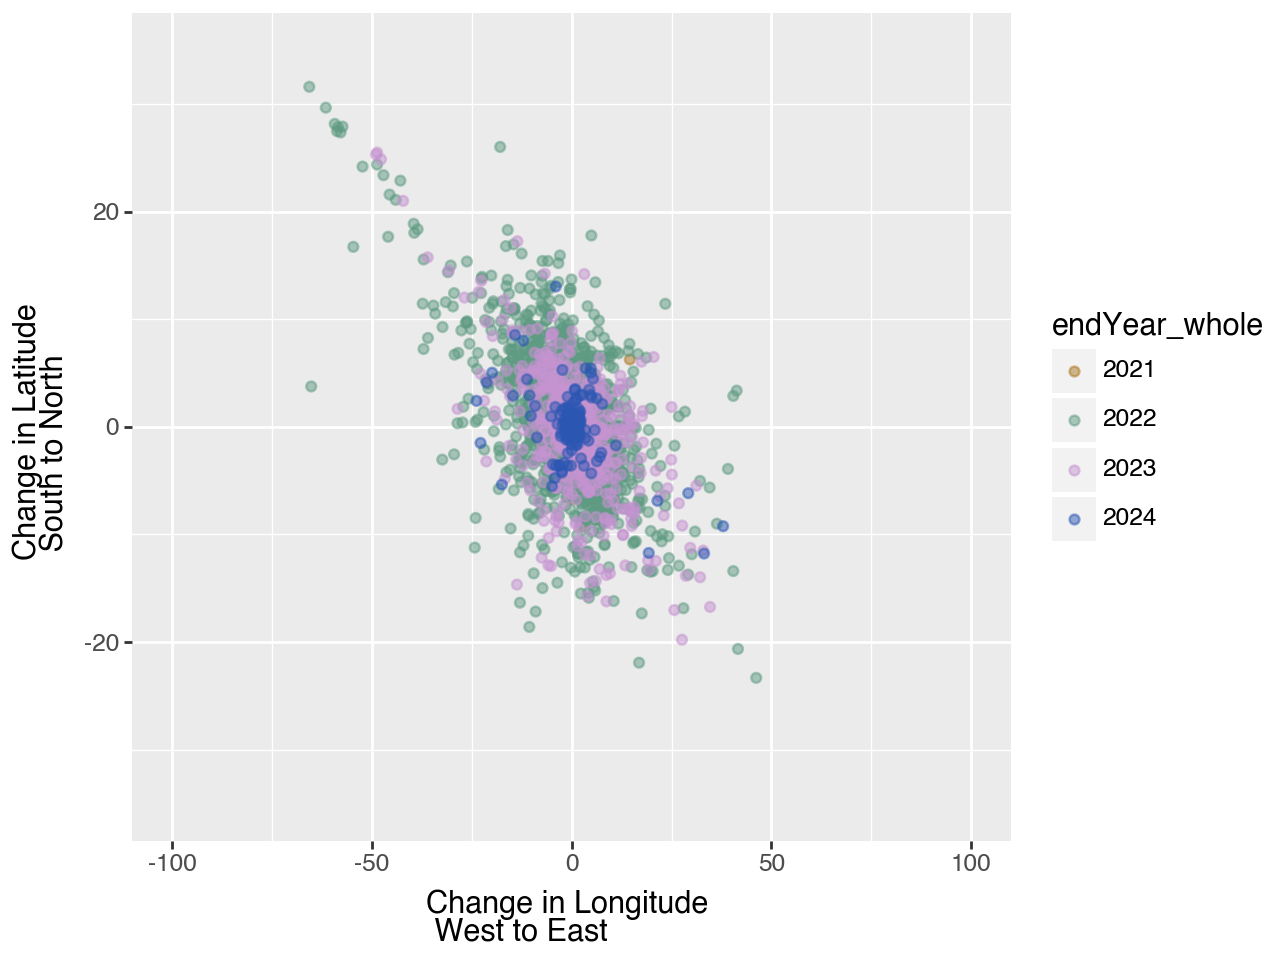

In [20]:
# Plot 1: change in direction of all points

year_colors = {"2021":"#AA7722",
               "2022":"#5E9B82",
               "2023":"#C593D1",
               "2024":"#2B57B3"
              }

all_time_scatter = (
    ggplot(mcc_seas_mon, aes(x = "changeLon", y = "changeLat", color = "endYear_whole")) 
    + geom_point(alpha = 0.5)
#    + stat_ellipse(type='t', level=0.95, linetype='dashed', size=1)
    + scale_color_manual(values=year_colors)
    + xlim(-100, 100)
    + ylim(-35, 35)
    + labs(x = "Change in Longitude \n West to East", y = "Change in Latitude \n South to North")
)

all_time_scatter.show()

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 1 rows containing missing values.


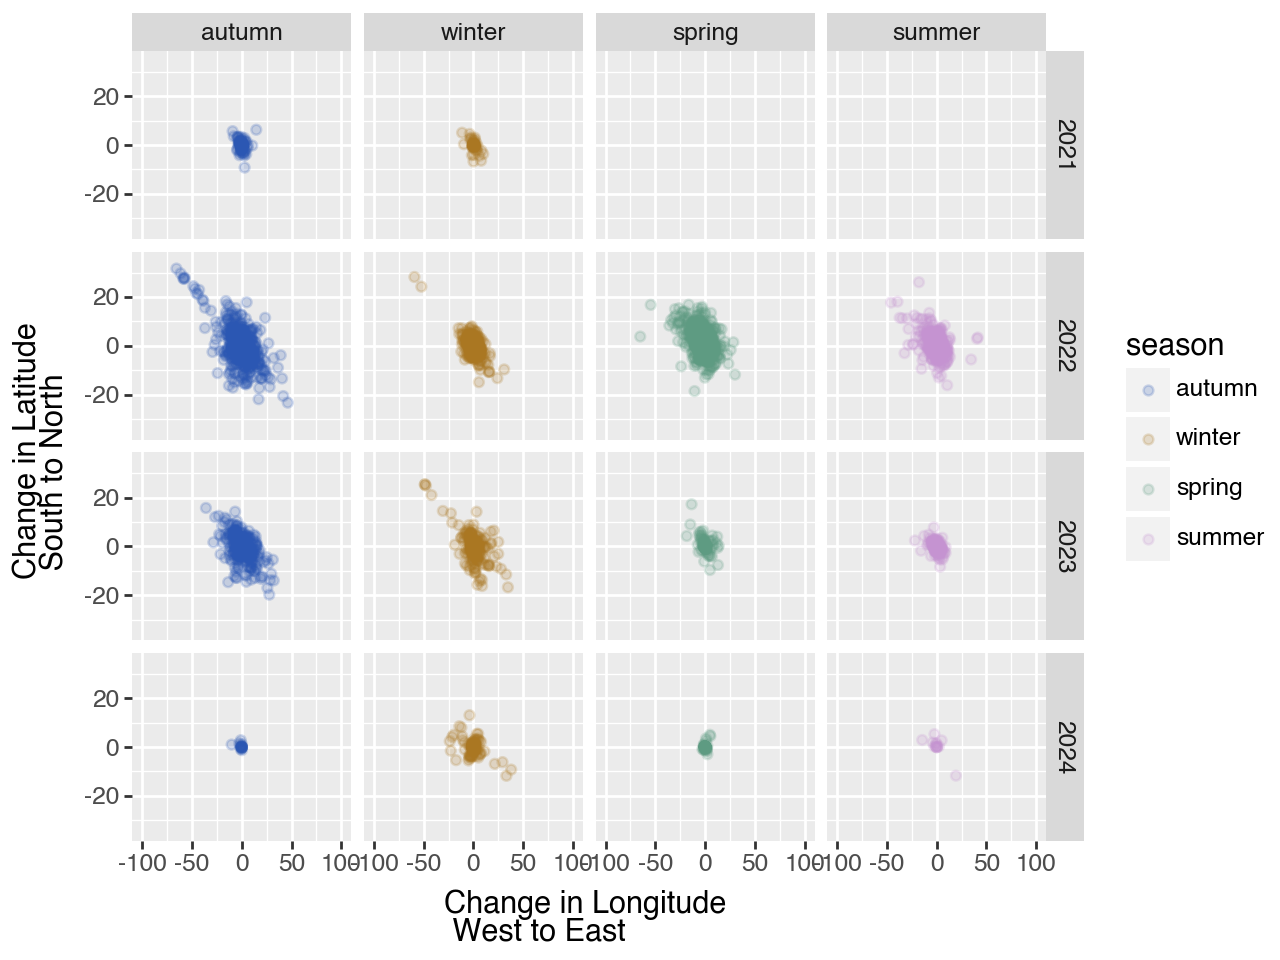

In [21]:
# Plot 1.5: change in direction, colored by season, facetted by year

season_colors = {"winter":"#AA7722",
               "spring":"#5E9B82",
               "summer":"#C593D1",
               "autumn":"#2B57B3"
              }

season_order = ["autumn", "winter", "spring", "summer"]
mcc_seas_mon["season"] = pd.Categorical(mcc_seas_mon["season"], categories=season_order, ordered=True)

seasonal_scatter = (
    ggplot(mcc_seas_mon, aes(x = "changeLon", y = "changeLat", color = "season")) 
    + geom_point(alpha = 0.2)
    # + stat_ellipse(type='t', level=0.95, size=1)
    + scale_color_manual(values=season_colors)
    # + facet_wrap("endYear_whole")
    + facet_grid("endYear_whole ~ season")
    + xlim(-100, 100)
    + ylim(-35, 35)
    + labs(x = "Change in Longitude \n West to East", y = "Change in Latitude \n South to North")
)

seasonal_scatter.show()

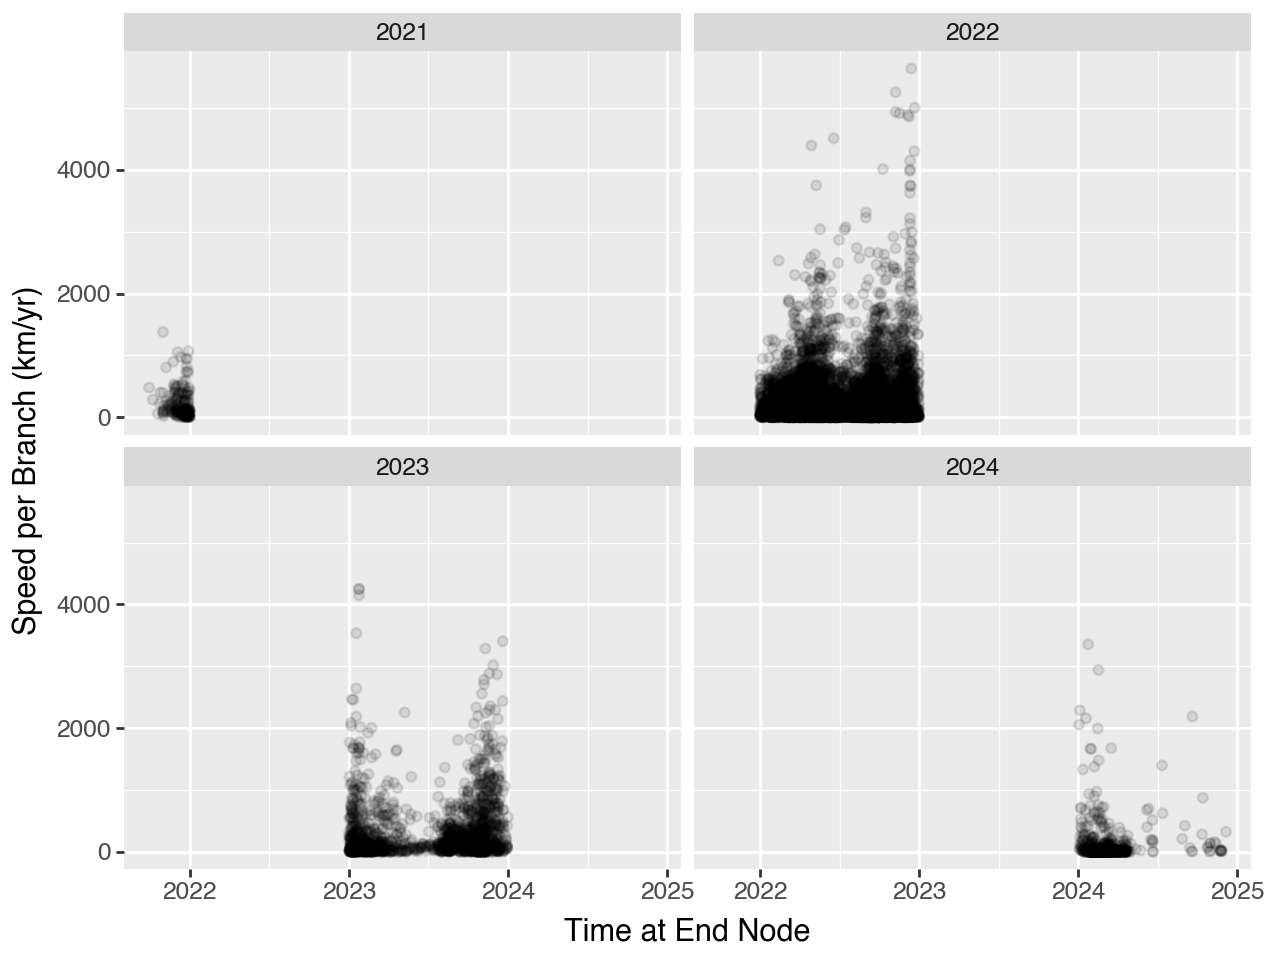

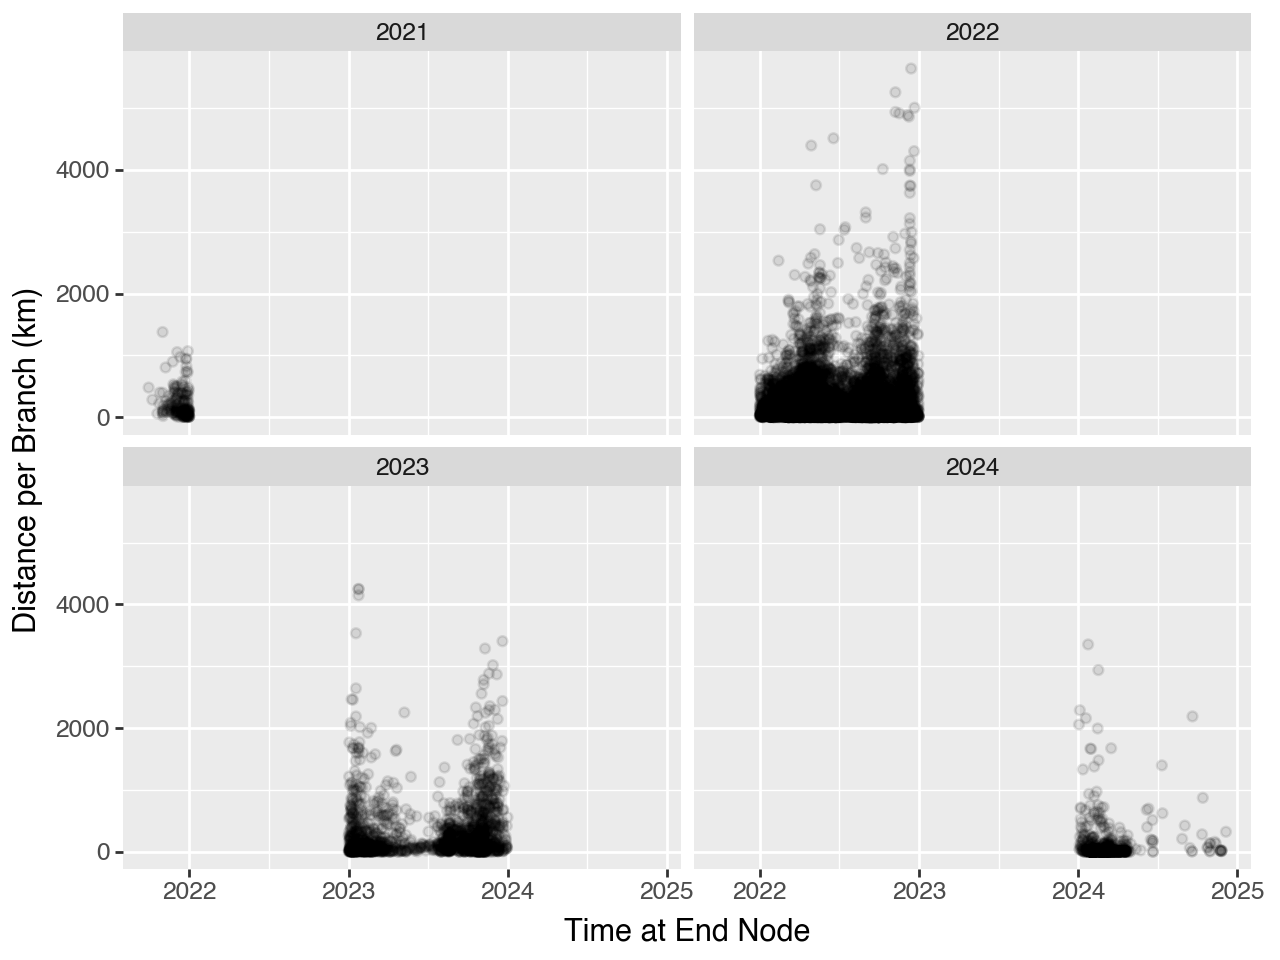

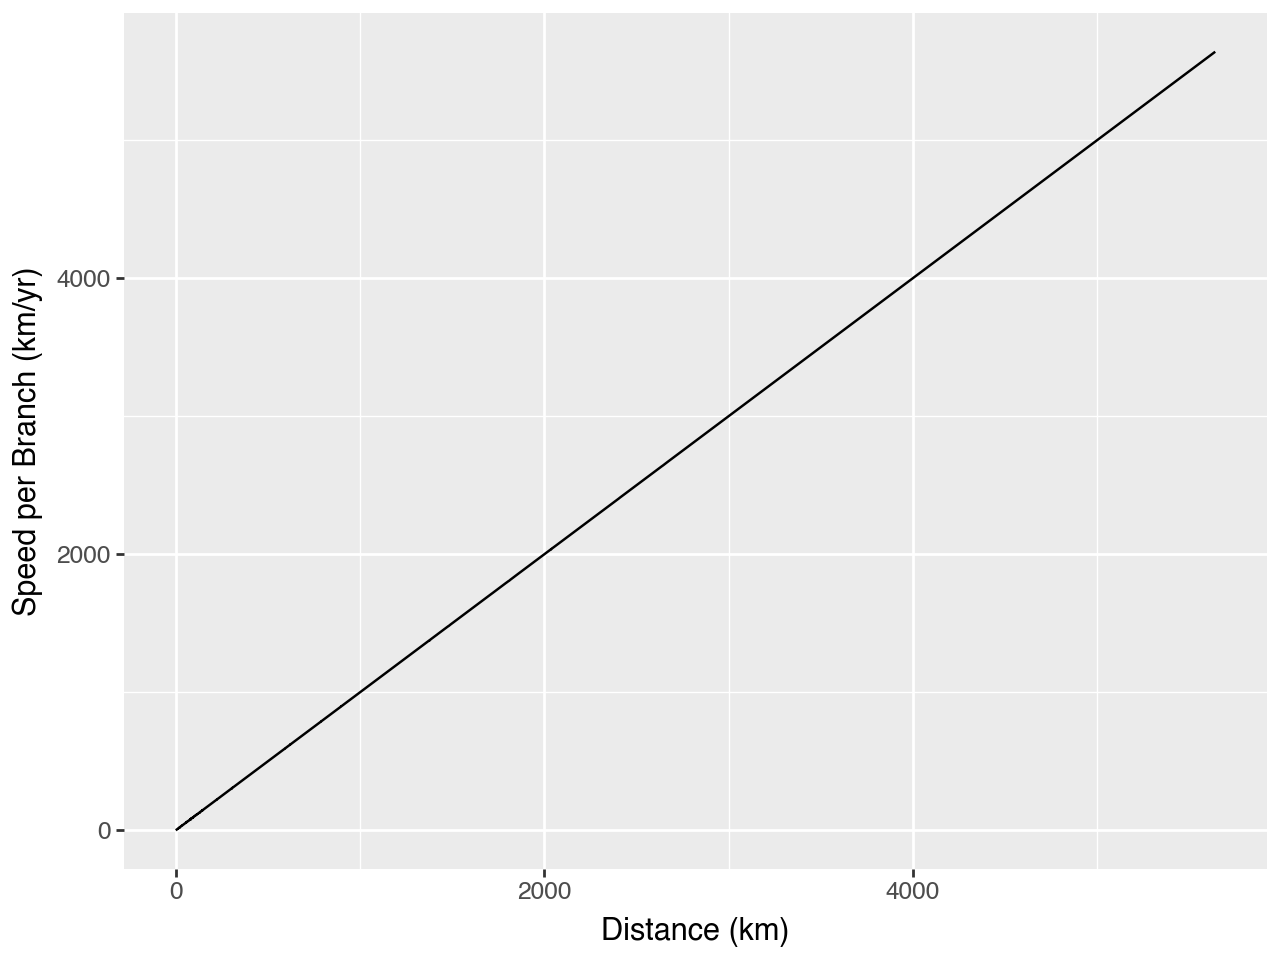

In [25]:
# Plots 2 and 3: speed and distance over time 

speed_over_time = (
    ggplot(mcc_seas_mon, aes(x = "endYear", y = "branchSpeed")) 
    + geom_point(alpha=0.1)
    + facet_wrap("endYear_whole")
    + labs(x = "Time at End Node", y = "Speed per Branch (km/yr)")
)

dist_over_time = (
    ggplot(mcc_seas_mon, aes(x = "endYear", y = "dist_km")) 
    + geom_point(alpha=0.1)
    + facet_wrap("endYear_whole")
    + labs(x = "Time at End Node", y = "Distance per Branch (km)")
)

dist_vs_speed = (
    ggplot(mcc_seas_mon, aes(x = "dist_km", y = "branchSpeed"))
    + geom_line()
    + labs(x = "Distance (km)", y = "Speed per Branch (km/yr)")
)

speed_over_time.show()
dist_over_time.show()
dist_vs_speed.show()

In [24]:
# Compute some statistics

In [60]:
# Statistics per year

stats_by_year_df = pd.DataFrame(["2021", "2022", "2023", "2024"]).rename({0:"year"}, axis = 1)

stats_by_year_df["total_speedperbranch"] = mcc_seas_mon.groupby('endYear_whole')['branchSpeed'].sum().to_list()

for idx, row in stats_by_year_df.iterrows():
    year = row["year"]
    if year == "2021":
        stats_by_year_df.at[idx, "mean_monthly_speed"] = row["total_speedperbranch"] / 4 # divide by month? or day?
    else:
        stats_by_year_df.at[idx, "mean_monthly_speed"] = row["total_speedperbranch"] / 12

stats_by_year_df["mean_speedperbranch_alt"] = mcc_seas_mon.groupby('endYear_whole')['branchSpeed'].mean().to_list() # I trust this more
stats_by_year_df["median_speedperbranch"] = mcc_seas_mon.groupby('endYear_whole')['branchSpeed'].median().to_list()
stats_by_year_df["sd_speedperbranch"] = mcc_seas_mon.groupby('endYear_whole')['branchSpeed'].std().to_list()

stats_by_year_df.head()

,year,total_speedperbranch,mean_monthly_speed,mean_speedperbranch_alt,median_speedperbranch,sd_speedperbranch
0,2021,3.908436e+04,9771.089749,222.070222,120.837233,245.211754
1,2022,2.310952e+06,192579.322202,246.422677,104.912816,405.661566
2,2023,5.751816e+05,47931.802690,337.349931,137.949823,499.923536
3,2024,7.451744e+04,6209.786681,97.408419,9.795179,301.899445


In [65]:
# Statistics per season

#mcc_seas_mon["season_year"] = mcc_seas_mon["endYear_whole"].astype(str) + "_" + mcc_seas_mon["season"].astype(str) # This is totally wrong
# If I make season_year this way, it considers December 2022 in the same season as January 2022, and they are NOT

# stats_by_season_df = pd.DataFrame(["2021_autumn", "2021_winter", "2022_spring", "2022_summer", "2022_autumn", "2022_winter",
#                                    "2023_spring", "2023_summer", "2023_autumn", "2023_winter",
#                                    "2024_spring", "2024_summer", "2024_autumn", "2024_winter"]).rename({0:"season"}, axis = 1)

stats_by_season_df["total_changeLat"] = mcc_seas_mon.groupby('season_year')['changeLat'].sum().to_list()
stats_by_season_df["avg_changeLat"] = mcc_seas_mon.groupby('season_year')['changeLat'].mean().to_list()
stats_by_season_df["total_changeLon"] = mcc_seas_mon.groupby('season_year')['changeLon'].sum().to_list()
stats_by_season_df["avg_changeLon"] = mcc_seas_mon.groupby('season_year')['changeLon'].mean().to_list()

#print(stats_by_season_df) # Table view

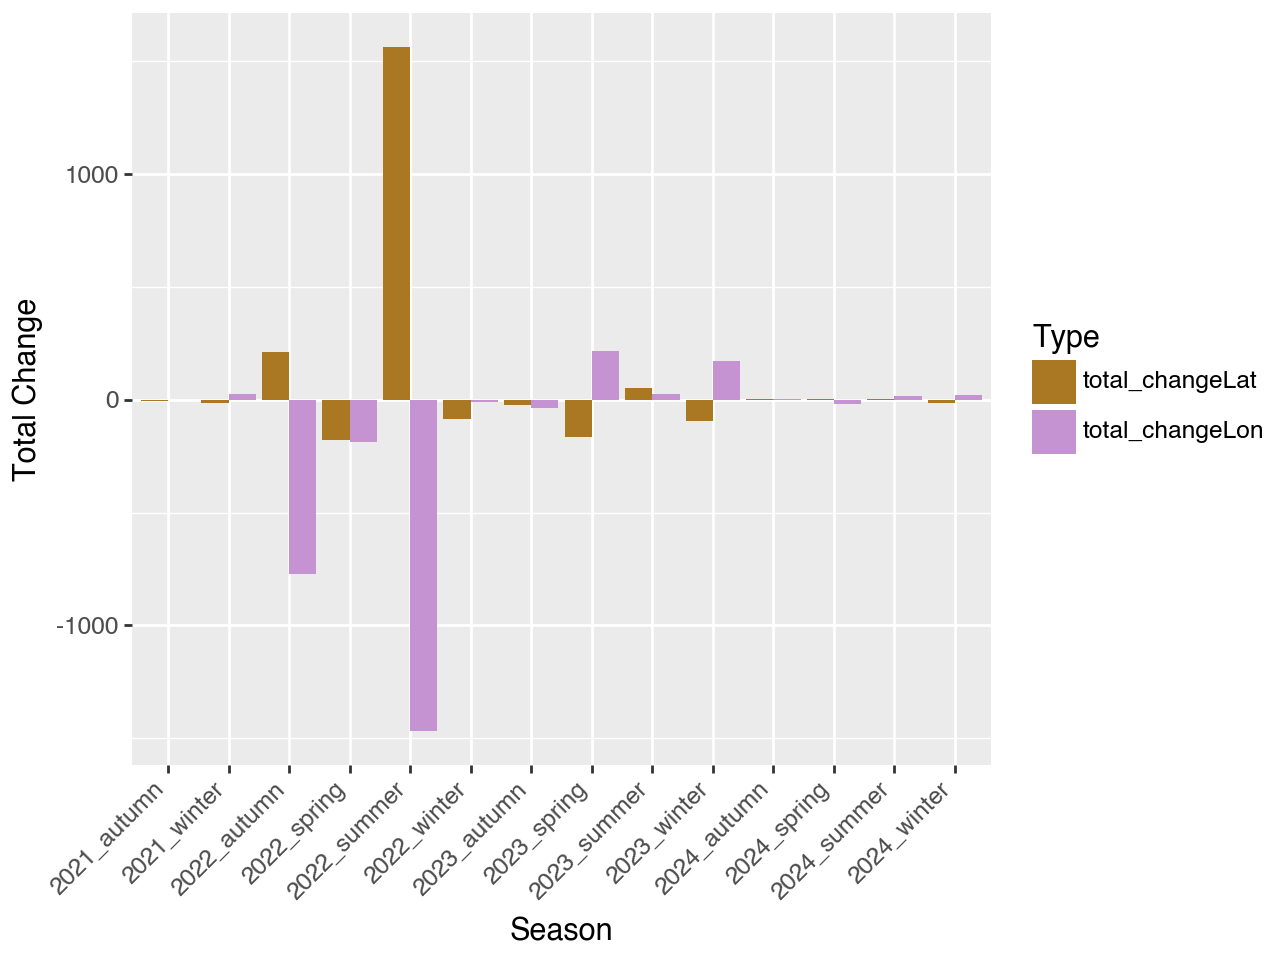

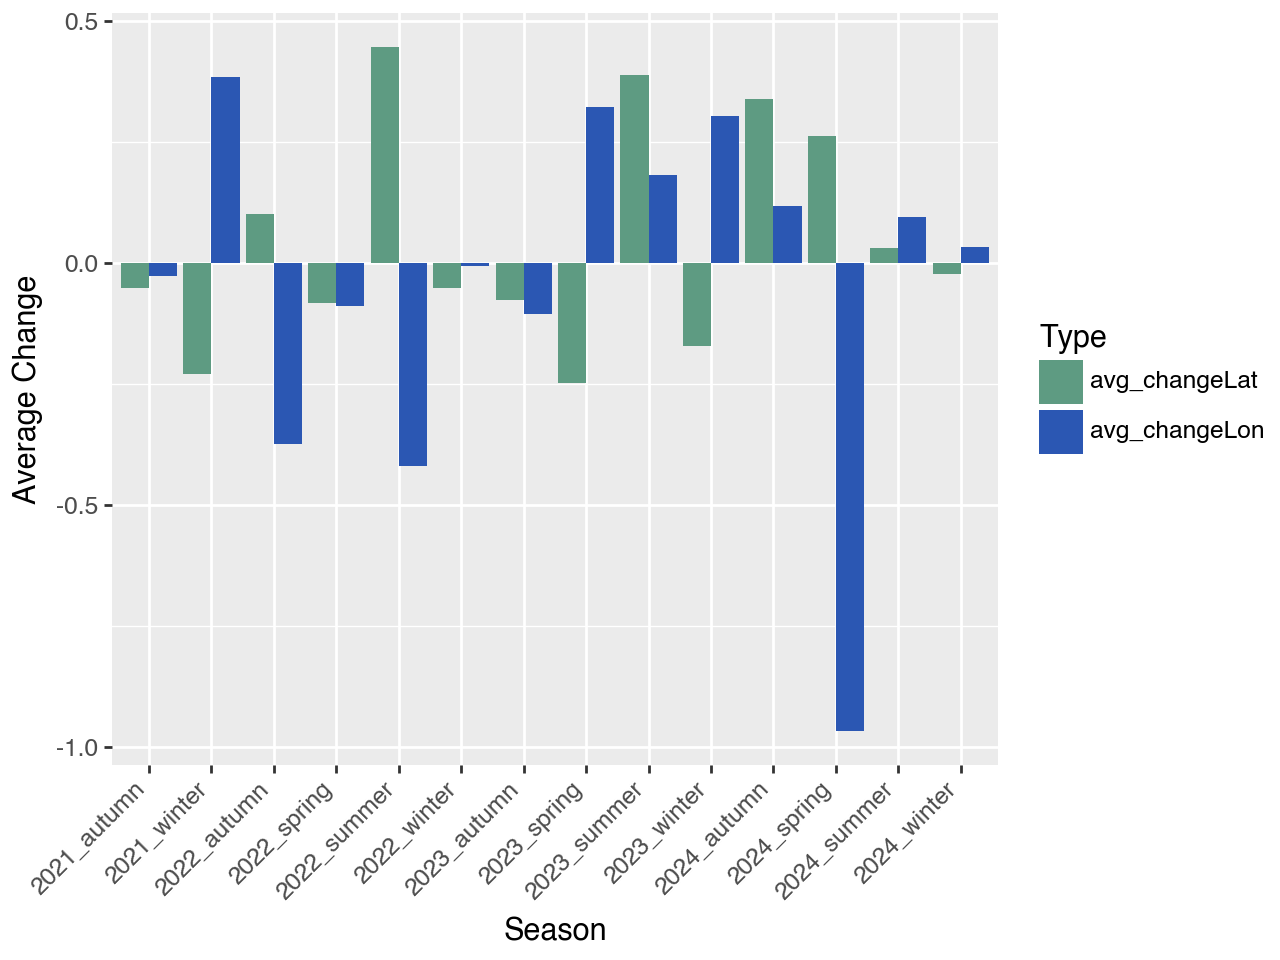

In [62]:
# Plot 4: change in lat and long per season

# Chat GPT says I need to reshape by df first
stats_by_season_long = stats_by_season_df.melt(
    id_vars=['season'], 
    value_vars=['total_changeLat', 'avg_changeLat', 'total_changeLon', 'avg_changeLon'],
    var_name='change_type',
    value_name='value'
)

#season_order = ["autumn", "winter", "spring", "summer"]
#stats_by_season_long["season"] = pd.Categorical(stats_by_season_long["season"], categories=season_order, ordered=True)

# Filter for averages
filtered_total = stats_by_season_long[stats_by_season_long["change_type"].isin(["total_changeLat", "total_changeLon"])]

# Filter for totals
filtered_avg = stats_by_season_long[stats_by_season_long["change_type"].isin(["avg_changeLat", "avg_changeLon"])]

total_change_per_season = (
    ggplot(filtered_total) 
    + geom_col(aes(x = "season", y='value', fill='change_type'), position='dodge')
    + labs(x = "Season", y = "Total Change", fill = "Type")
    + scale_fill_manual(values={'total_changeLat': '#AA7722','total_changeLon': '#C593D1'})
    + theme(axis_text_x=element_text(rotation=45, hjust=1))
)

avg_change_per_season = (
    ggplot(filtered_avg) 
    + geom_col(aes(x = "season", y='value', fill='change_type'), position='dodge')
    + labs(x = "Season", y = "Average Change", fill = "Type")
    + scale_fill_manual(values={'avg_changeLat': '#5E9B82', 'avg_changeLon': '#2B57B3'})
    + theme(axis_text_x=element_text(rotation=45, hjust=1))
)

total_change_per_season.show()
avg_change_per_season.show()

In [44]:
# Statistics per month_year

mcc_seas_mon["month_year"] = mcc_seas_mon["endYear_whole"].astype(str) + "_" + mcc_seas_mon["month"].astype(str)

stats_by_month_df = pd.DataFrame(["2021_september", "2021_october","2021_november","2021_december",
                                  "2022_january", "2022_february", "2022_march", "2022_april", "2022_may", "2022_june",
                                  "2022_july", "2022_august", "2022_september", "2022_october", "2022_november", "2022_december",
                                  "2023_january", "2023_february", "2023_march", "2023_april", "2023_may", "2023_june",
                                  "2023_july", "2023_august", "2023_september", "2023_october", "2023_november", "2023_december",
                                  "2024_january", "2024_february", "2024_march", "2024_april", "2024_may", "2024_june",
                                  "2024_july", "2024_august", "2024_september", "2024_october", "2024_november", "2024_december"]).rename({0:"month"}, axis = 1)

stats_by_month_df["avg_startLat"] = mcc_seas_mon.groupby('month_year')['startLat'].mean().to_list()
stats_by_month_df["avg_startLon"] = mcc_seas_mon.groupby('month_year')['startLon'].mean().to_list()
stats_by_month_df["avg_endLat"] = mcc_seas_mon.groupby('month_year')['endLat'].mean().to_list()
stats_by_month_df["avg_endLon"] = mcc_seas_mon.groupby('month_year')['endLon'].mean().to_list()

#print(stats_by_month_df) # Table view

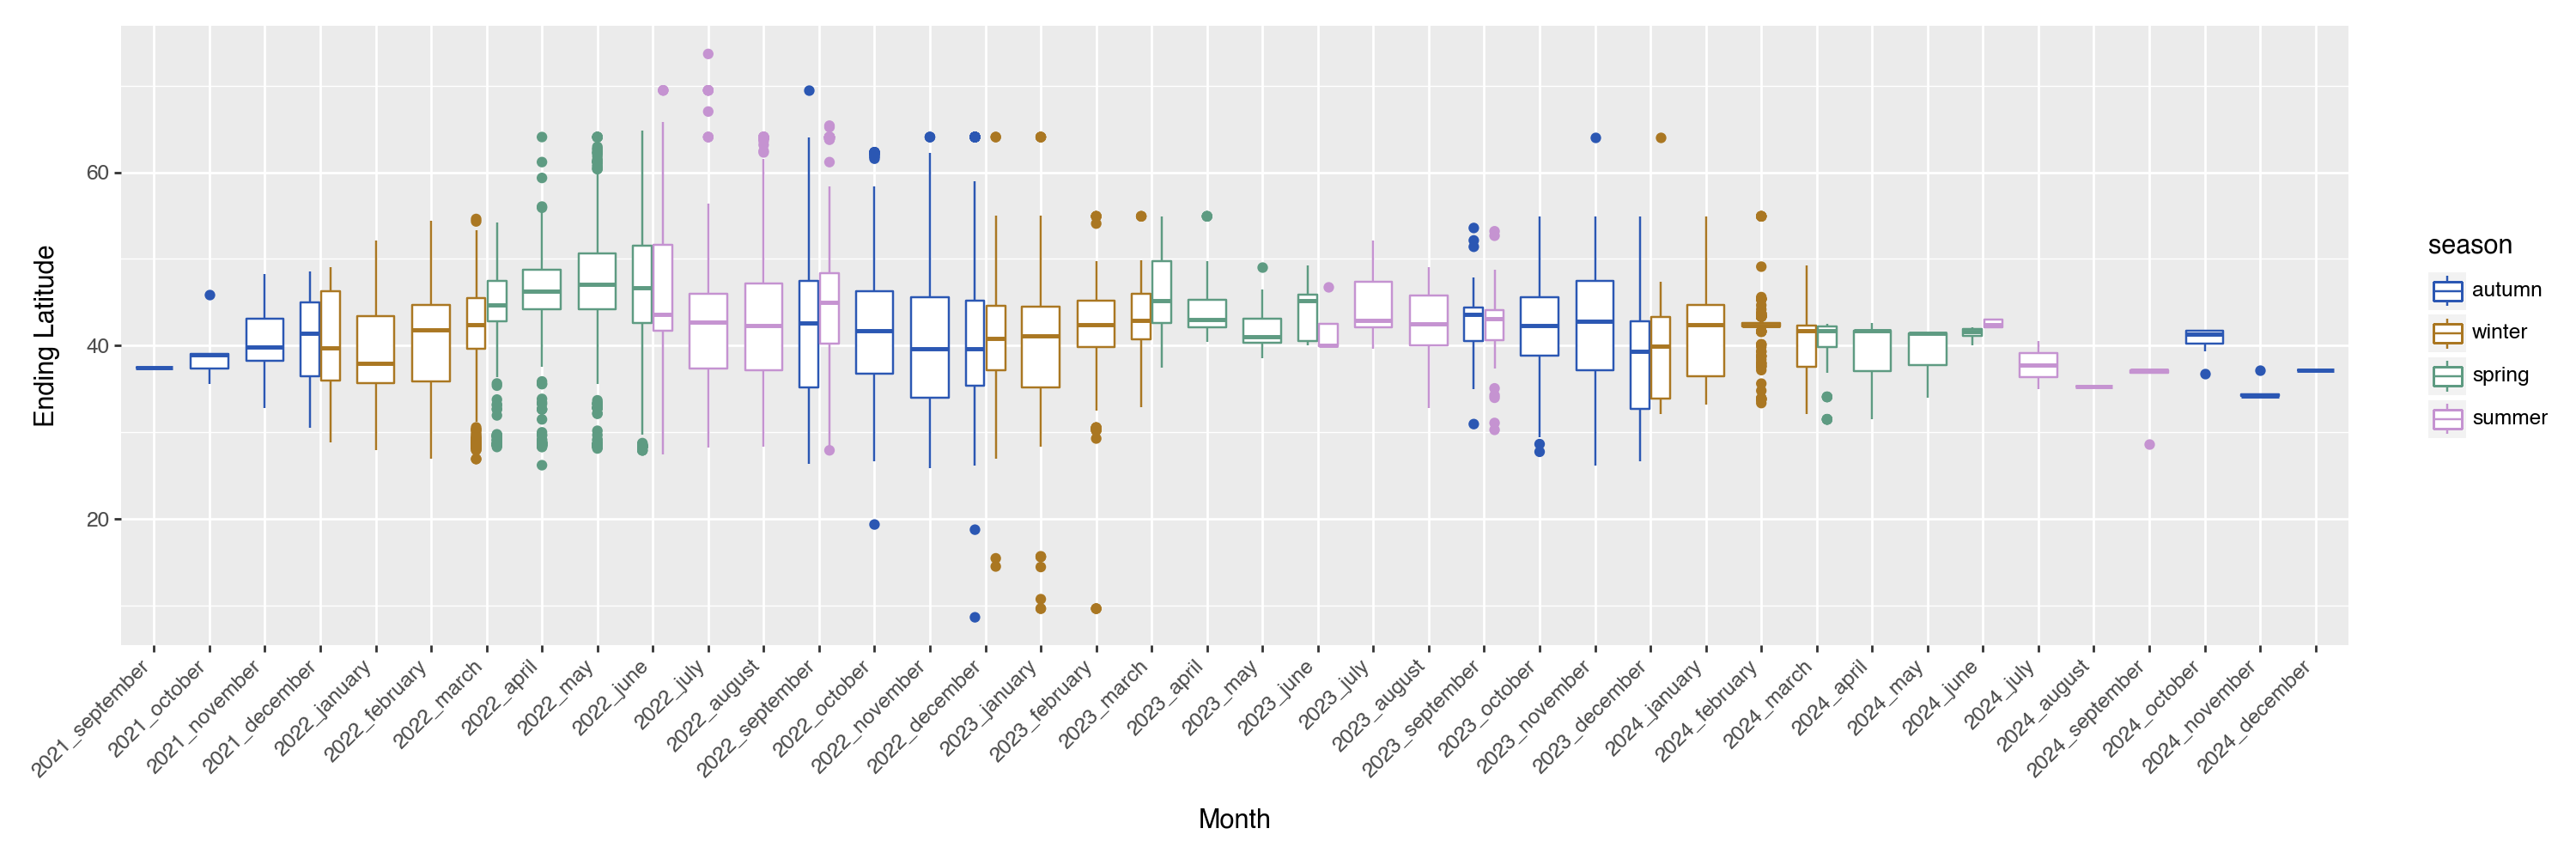

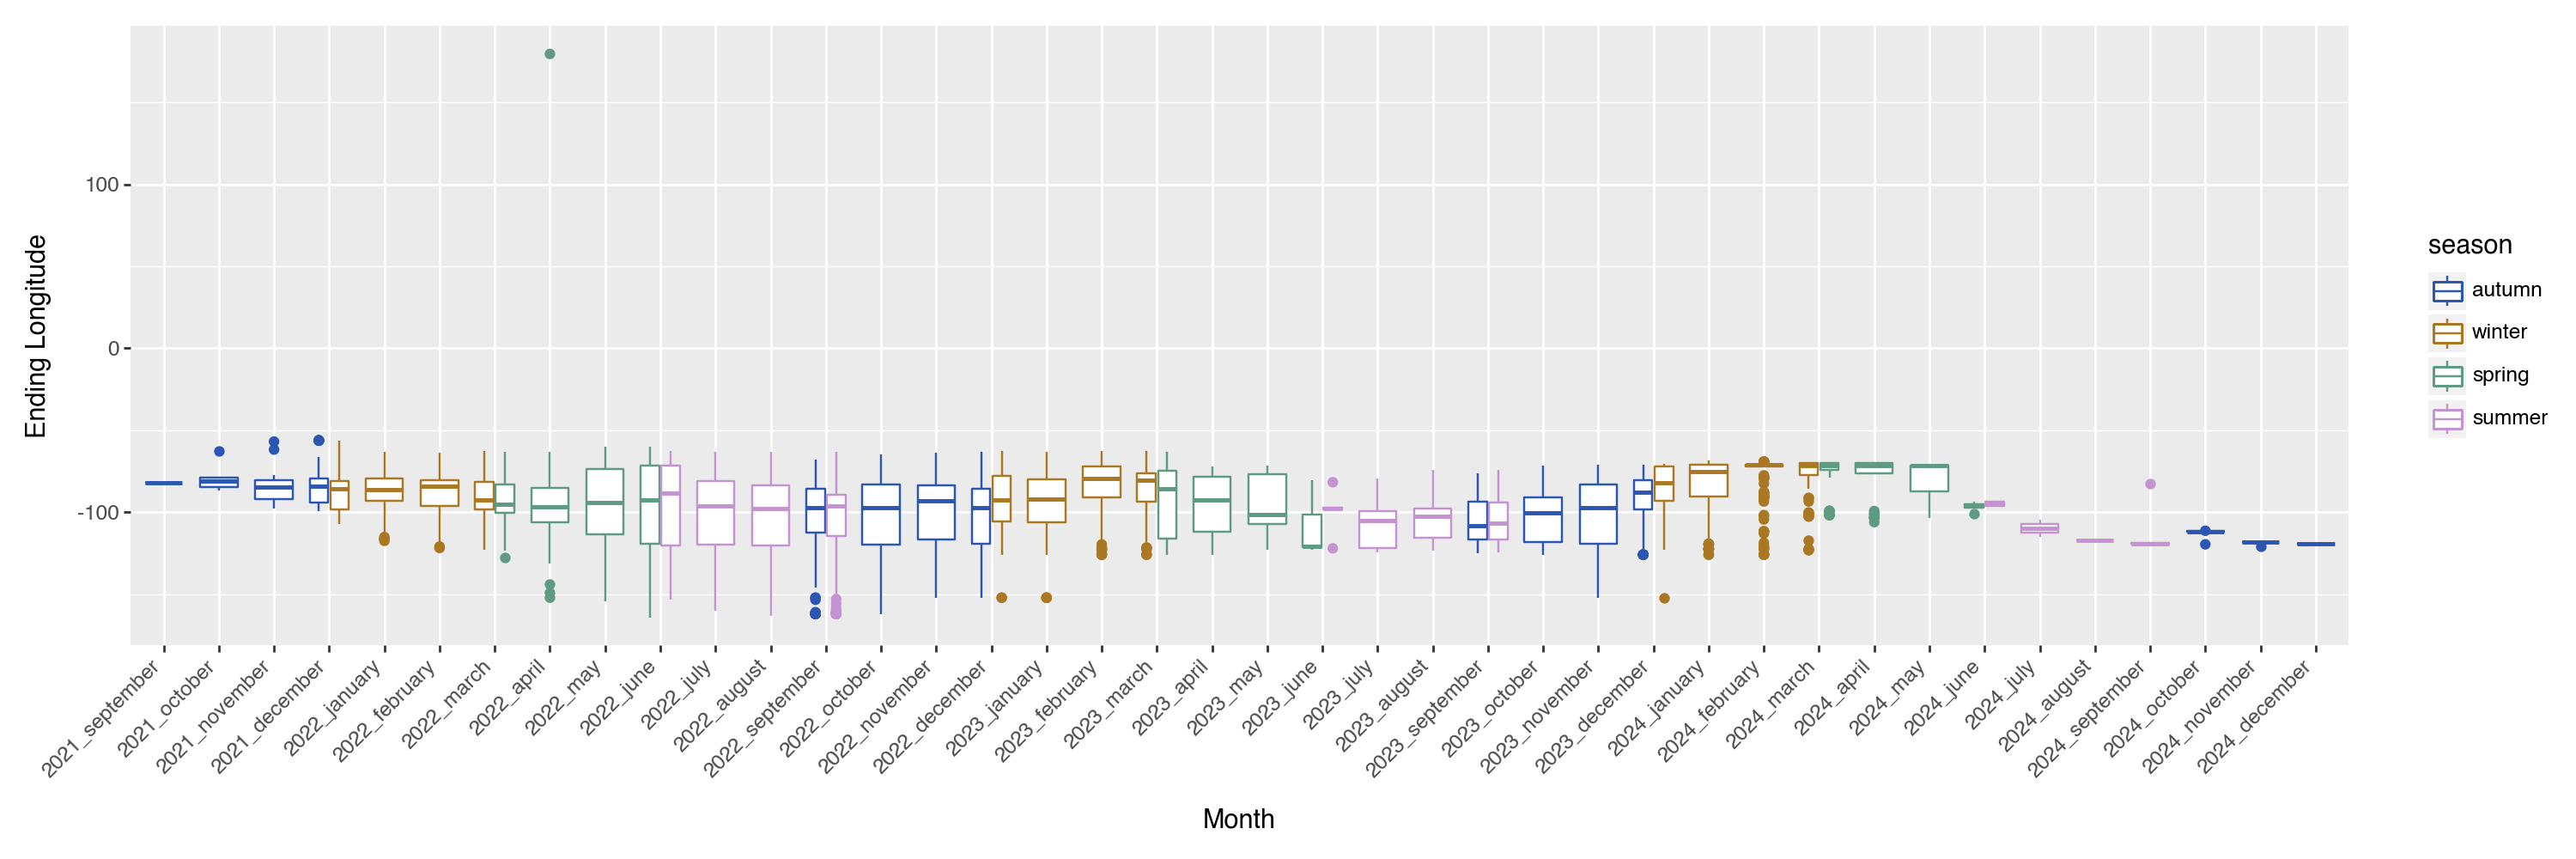

In [59]:
# Plot 5: average lat and lon per month

mcc_seas_mon["month_year"] = mcc_seas_mon["month_year"].astype(str)

month_order = ["2021_september", "2021_october","2021_november","2021_december", "2022_january", "2022_february", "2022_march", "2022_april", "2022_may", "2022_june",
               "2022_july", "2022_august", "2022_september", "2022_october", "2022_november", "2022_december","2023_january", "2023_february", "2023_march", "2023_april", 
               "2023_may", "2023_june", "2023_july", "2023_august", "2023_september", "2023_october", "2023_november", "2023_december", "2024_january", "2024_february", 
               "2024_march", "2024_april", "2024_may", "2024_june","2024_july", "2024_august", "2024_september", "2024_october", "2024_november", "2024_december"]

mcc_seas_mon["month_year"] = pd.Categorical(mcc_seas_mon["month_year"], categories=month_order, ordered=True)

avg_latitude = (
    ggplot(mcc_seas_mon)
#    + geom_boxplot(aes(x = "factor(month_year)", y = "startLat", color = "season"))
    + geom_boxplot(aes(x = "factor(month_year)", y = "endLat", color = "season"))
    + labs(x = "Month", y = "Ending Latitude")
    + scale_color_manual(values = season_colors)
    + theme(axis_text_x=element_text(rotation=45, hjust=1), figure_size = (15, 5))
)


avg_longitude = (
    ggplot(mcc_seas_mon)
#    + geom_boxplot(aes(x = "factor(month_year)", y = "startLon", color = "season"))
    + geom_boxplot(aes(x = "factor(month_year)", y = "endLon", color = "season"))
    + labs(x = "Month", y = "Ending Longitude")
    + scale_color_manual(values = season_colors)
    + theme(axis_text_x=element_text(rotation=45, hjust=1), figure_size = (15, 5))
)

avg_latitude.show()
avg_longitude.show()

In [28]:
# Match lat/long to a flyway

In [30]:
# Anna's FIPS code assignment function

# def get_block_group_fips(lat, lon):
#     url = f"https://geo.fcc.gov/api/census/block/find?latitude={lat}&longitude={lon}&censusYear=2010&format=json"
#     response = requests.get(url)
#     data = response.json()
#     block_fips = data['Block']['FIPS']
#     block_group_fips = block_fips[:12]  # Truncate to 12 digits
#     return block_group_fips

# # Example
# print(get_block_group_fips(40.7128, -74.0060))  # Should return 12-digit FIPS

In [31]:
# First try by Clara

# from geopy.geocoders import Nominatim

# geolocator = Nominatim(user_agent="cm_plotting_app")

# def state(df, column1, column2):
#     coords = str((df[column1], df[column2]))
#     location = geolocator.reverse(coords)
#     state = location.raw["address"].get("state")
#     return state

In [32]:
# Second try by Chat GPT - too slow!

# Set up geolocator globally
# geolocator = Nominatim(user_agent="geo_lookup_app")

# def reverse_geocode(lat, lon):
#     try:
#         location = geolocator.reverse((lat, lon), language='en')
#         if location and 'state' in location.raw['address']:
#             return location.raw['address']['state']
#         else:
#             return None
#     except GeocoderTimedOut:
#         time.sleep(1)
#         return reverse_geocode(lat, lon)  # Retry once
#     except Exception as e:
#         print(f"Error for ({lat}, {lon}): {e}")
#         return None

# def add_state_column(df, lat_col, lon_col):
#     df["state"] = df.apply(lambda row: reverse_geocode(row[lat_col], row[lon_col]), axis=1)
#     return df

In [33]:
#mcc_seasons["startState"] = add_state_column(mcc_seasons, "startLat", "startLon")

In [212]:
# Need a shapefile to dictate polygon boundaries

# Load in the NaturalEarth shapefile as your map
states_path = "./metadata/ne_110m_admin_1_states_provinces/ne_110m_admin_1_states_provinces.shp"
states_gdf = gpd.read_file(states_path)

# for now, use this for Canada and Mexico - will need a new one
countries_path = "./metadata/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp"
countries_gdf = gpd.read_file(countries_path)

In [213]:
# Filter for U.S. states and desired countries

# Filter for US States
us_states = states_gdf[states_gdf['admin'] == 'United States of America']

# List of countries to include
country_list = ["Canada", "Mexico"]

selected_countries = countries_gdf[countries_gdf['ADMIN'].isin(country_list)]

In [214]:
# Reproject, just in case
selected_countries = selected_countries.to_crs("EPSG:4326")

# Combine both GeoDataFrames
combined_gdf = pd.concat([us_states, selected_countries], ignore_index=True)

In [215]:
# Rename and filter some columns in the combined_gdf to make it neater

combined_gdf["location"] = combined_gdf["name"].combine_first(combined_gdf["NAME"])
combined_gdf["ISO"] = combined_gdf["iso_a2"].combine_first(combined_gdf["ISO_A2"])
combined_gdf["ADM0"] = combined_gdf["adm0_a3"].combine_first(combined_gdf["ADM0_A3"])
columns = ["geometry", "location", "adm1_code", "ISO", "ADM0", "region", "sub_code", "region_sub"]
combined_gdf_filt = combined_gdf.loc[0:, columns]

combined_gdf_filt = combined_gdf_filt.to_crs("EPSG:4326") # Ensure same CRS
#print(combined_gdf_filt)

/Users/claramal/miniconda3/lib/python3.11/site-packages/geopandas/geodataframe.py:1819: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
/Users/claramal/miniconda3/lib/python3.11/site-packages/geopandas/geodataframe.py:1819: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
/Users/claramal/miniconda3/lib/python3.11/site-packages/geopandas/geodataframe.py:1819: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at onc

In [216]:
# Create geometries for each start and end point in the MCC tree

mcc_seas_mon['startGeometry'] = mcc_seas_mon.apply(lambda row: Point(row['startLon'], row['startLat']), axis=1)
mcc_seas_mon['endGeometry'] = mcc_seas_mon.apply(lambda row: Point(row['endLon'], row['endLat']), axis=1)

geop_mcc_seas_mon_start = gpd.GeoDataFrame(mcc_seas_mon, geometry='startGeometry', crs="EPSG:4326")
geop_mcc_seas_mon_end = gpd.GeoDataFrame(mcc_seas_mon, geometry='endGeometry', crs="EPSG:4326")

geop_mcc_seas_mon_start = geop_mcc_seas_mon_start.set_crs("EPSG:4326", allow_override=True)
geop_mcc_seas_mon_end = geop_mcc_seas_mon_end.set_crs("EPSG:4326", allow_override=True)
# print(geop_mcc_seas_mon["startGeometry"])

# print(geop_mcc_seas_mon)

In [217]:
# Function: use gpd.sjoin to assign coordinates to the state (made by Chat GPT)

def assign_state(df, geom_col, states_gdf, new_col):
    temp = df.set_geometry(geom_col, inplace=False)

    # # CRS check and force match
    # if temp.crs != states_gdf.crs:
    #     temp = temp.to_crs(states_gdf.crs)

    result = gpd.sjoin(temp, states_gdf[["location", "geometry"]], how="left", predicate="within")
    state_series = result.rename(columns={"location": new_col})[new_col]
    return state_series.reindex(df.index)

In [218]:
geop_mcc_seas_mon["startState"] = assign_state(geop_mcc_seas_mon_start, "startGeometry", combined_gdf_filt, "startState")
geop_mcc_seas_mon["endState"] = assign_state(geop_mcc_seas_mon_end, "endGeometry", combined_gdf_filt, "endState")

In [219]:
geop_mcc_seas_mon.head(8)

,node1,node2,length,startLon,startLat,endLon,endLat,endNodeL,startNodeL,startYear,...,endYear_whole,season,month,dist_km,changeYear,branchSpeed,startGeometry,endGeometry,startState,endState
0,6014,6015,0.134134,-77.192847,39.606088,-81.985138,37.488593,0.134134,0.000000,2021.609902,...,2021,autumn,unknown,479.256583,0.134134,479.122449,POINT (-77.1928469762194 39.6060875436214),POINT (-81.98514 37.48859),Maryland,Virginia
1,6015,9034,0.023139,-81.985138,37.488593,-84.675856,38.896095,0.157272,0.134134,2021.744036,...,2021,autumn,unknown,282.768108,0.023139,282.744969,POINT (-81.9851378125235 37.4885929790095),POINT (-84.67586 38.89609),Virginia,Kentucky
2,9034,9035,0.031183,-84.675856,38.896095,-84.255735,38.488669,0.188455,0.157272,2021.767175,...,2021,autumn,unknown,58.150793,0.031183,58.119610,POINT (-84.6758557078282 38.8960948578632),POINT (-84.25574 38.48867),Kentucky,Kentucky
3,9035,9141,0.012011,-84.255735,38.488669,-86.741516,38.975548,0.200467,0.188455,2021.798358,...,2021,autumn,unknown,222.790755,0.012011,222.778744,POINT (-84.2557354887159 38.4886689209951),POINT (-86.74152 38.97555),Kentucky,Indiana
4,9035,9036,0.015212,-84.255735,38.488669,-80.850620,36.146270,0.203668,0.188455,2021.798358,...,2021,autumn,unknown,398.296537,0.015212,398.281324,POINT (-84.2557354887159 38.4886689209951),POINT (-80.85062 36.14627),Kentucky,North Carolina
5,9036,9037,0.016818,-80.850620,36.146270,-80.201810,35.605809,0.220485,0.203668,2021.813570,...,2021,autumn,unknown,83.838595,0.016818,83.821778,POINT (-80.8506195617789 36.1462704724088),POINT (-80.20181 35.60581),North Carolina,North Carolina
6,6014,11364,0.221734,-77.192847,39.606088,-62.640105,45.879399,0.221734,0.000000,2021.609902,...,2021,autumn,unknown,1377.292882,0.221734,1377.071148,POINT (-77.1928469762194 39.6060875436214),POINT (-62.64011 45.8794),Maryland,NaN
7,9036,9053,0.018677,-80.850620,36.146270,-78.196999,39.021812,0.222345,0.203668,2021.813570,...,2021,autumn,unknown,395.927614,0.018677,395.908937,POINT (-80.8506195617789 36.1462704724088),POINT (-78.197 39.02181),North Carolina,Virginia
